In [11]:
# ============================================
# NIGERIAFLOODWATCH
# Task 3.4: Local Lokoja Floodplain Analysis
# ============================================

from pathlib import Path
import zipfile
import warnings

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from shapely.geometry import Polygon, MultiPolygon
from shapely.validation import explain_validity

import os

os.environ["SHAPE_RESTORE_SHX"] = "YES"

warnings.filterwarnings("ignore", category=UserWarning)

# Project root
PROJECT_ROOT = Path("/workspaces/nigeria-flood-watch") 

# Source data directory
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Processed data directory
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Create processed directory if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Source archives
COPERNICUS_ZIP = (
        RAW_DIR /
            "EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip"
)

LOKOJA_LGA_ZIP = (
        RAW_DIR /
            "lokoja_lga_utm32n.zip"
)

print("Project root:", PROJECT_ROOT)
print("Raw directory:", RAW_DIR)
print("Processed directory:", PROCESSED_DIR)

print("\nCopernicus archive exists:", COPERNICUS_ZIP.exists())
print("Lokoja LGA archive exists:", LOKOJA_LGA_ZIP.exists())


Project root: /workspaces/nigeria-flood-watch
Raw directory: /workspaces/nigeria-flood-watch/data/raw
Processed directory: /workspaces/nigeria-flood-watch/data/processed

Copernicus archive exists: True
Lokoja LGA archive exists: True


Inspecting the corpernicus archive

In [12]:
if not COPERNICUS_ZIP.exists():
    raise FileNotFoundError(
        f"Copernicus archive not found: {COPERNICUS_ZIP}"
    )

with zipfile.ZipFile(COPERNICUS_ZIP, "r") as archive:

    archive_contents = archive.namelist()

    print("Total files in archive:", len(archive_contents))
    print("\nARCHIVE CONTENTS:\n")

    for filename in archive_contents:
        print(filename)

Total files in archive: 52

ARCHIVE CONTENTS:

EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.dbf
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.kmz
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.prj
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shp
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shx
EMSR314_02LOKOJA_DEL_v1_built_up_a.dbf
EMSR314_02LOKOJA_DEL_v1_built_up_a.kmz
EMSR314_02LOKOJA_DEL_v1_built_up_a.prj
EMSR314_02LOKOJA_DEL_v1_built_up_a.shp
EMSR314_02LOKOJA_DEL_v1_built_up_a.shx
EMSR314_02LOKOJA_DEL_v1_facilities_p.dbf
EMSR314_02LOKOJA_DEL_v1_facilities_p.kmz
EMSR314_02LOKOJA_DEL_v1_facilities_p.prj
EMSR314_02LOKOJA_DEL_v1_facilities_p.shp
EMSR314_02LOKOJA_DEL_v1_facilities_p.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_a.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_a.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_a.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_l.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_l.kmz
EMSR314_02LOKOJA_DEL_v1_

In [13]:
# Identify relevant shapefile components

keywords = [
    "observed_event_a",
    "area_of_interest_a",
    "hydrography_a",
    "hydrography_l",
    "built_up_a",
    "transportation_l",
    "physiography_l"
]

print("\nRELEVANT FILES:\n")

for filename in archive_contents:
    if any(keyword.lower() in filename.lower() for keyword in keywords):
        print(filename)


RELEVANT FILES:

EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.dbf
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.kmz
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.prj
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shp
EMSR314_02LOKOJA_DEL_v1_area_of_interest_a.shx
EMSR314_02LOKOJA_DEL_v1_built_up_a.dbf
EMSR314_02LOKOJA_DEL_v1_built_up_a.kmz
EMSR314_02LOKOJA_DEL_v1_built_up_a.prj
EMSR314_02LOKOJA_DEL_v1_built_up_a.shp
EMSR314_02LOKOJA_DEL_v1_built_up_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_a.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_a.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_a.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_a.shx
EMSR314_02LOKOJA_DEL_v1_hydrography_l.dbf
EMSR314_02LOKOJA_DEL_v1_hydrography_l.kmz
EMSR314_02LOKOJA_DEL_v1_hydrography_l.prj
EMSR314_02LOKOJA_DEL_v1_hydrography_l.shp
EMSR314_02LOKOJA_DEL_v1_hydrography_l.shx
EMSR314_02LOKOJA_DEL_v1_observed_event_a.dbf
EMSR314_02LOKOJA_DEL_v1_observed_event_a.kmz
EMSR314_02LOKOJA_DEL_v1_observed_event_a.p

loading and inspecting the flood polygons

In [16]:
from pathlib import Path
import zipfile

EXTRACT_DIR = RAW_DIR / "EMSR314_02_extracted"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(COPERNICUS_ZIP, "r") as archive:
    archive.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Extraction directory:", EXTRACT_DIR)

Extraction completed.
Extraction directory: /workspaces/nigeria-flood-watch/data/raw/EMSR314_02_extracted


In [17]:
flood_shapefiles = list(
    EXTRACT_DIR.rglob("EMSR314_02LOKOJA_DEL_v1_observed_event_a.shp")
)

if len(flood_shapefiles) != 1:
    raise FileNotFoundError(
        f"Expected one observed flood shapefile, found: {len(flood_shapefiles)}"
    )

flood_shapefile = flood_shapefiles[0]

print("Observed flood shapefile:", flood_shapefile)

print("\nSupporting files:")

for extension in [".shp", ".shx", ".dbf", ".prj"]:
    matches = list(
        flood_shapefile.parent.glob(f"{flood_shapefile.stem}{extension}")
    )
    print(extension, ":", bool(matches))

Observed flood shapefile: /workspaces/nigeria-flood-watch/data/raw/EMSR314_02_extracted/EMSR314_02LOKOJA_DEL_v1_observed_event_a.shp

Supporting files:
.shp : True
.shx : True
.dbf : True
.prj : True


In [ ]:
# Allow GDAL to reconstruct missing SHX files in the writable directory
os.environ["SHAPE_RESTORE_SHX"] = "YES"

flood_gdf = gpd.read_file(flood_shapefile)

print("Flood layer loaded successfully.")

print("\nFeature count:", len(flood_gdf))
print("CRS:", flood_gdf.crs)

print("\nGeometry types:")
print(flood_gdf.geom_type.value_counts())

print("\nColumns:")
print(flood_gdf.columns.tolist())

print("\nBounding box:")
print(flood_gdf.total_bounds)

Flood layer loaded successfully.

Feature count: 1509
CRS: EPSG:4326

Geometry types:
Polygon         1496
MultiPolygon      13
Name: count, dtype: int64

Columns:
['event_type', 'obj_desc', 'det_method', 'notation', 'dmg_src_id', 'geometry']

Bounding box:
[6.70362823 7.7284658  7.00494625 7.97969175]


In [19]:
LGA_EXTRACT_DIR = RAW_DIR / "lokoja_lga_extracted"

LGA_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LOKOJA_LGA_ZIP, "r") as archive:
    archive.extractall(LGA_EXTRACT_DIR)

lga_shapefiles = list(LGA_EXTRACT_DIR.rglob("*.shp"))

if len(lga_shapefiles) != 1:
    raise ValueError(
        f"Expected one LGA shapefile, found: {len(lga_shapefiles)}"
    )

lokoja_lga = gpd.read_file(lga_shapefiles[0])

print("LOKOJA LGA LOADED")
print("Features:", len(lokoja_lga))
print("CRS:", lokoja_lga.crs)
print("Geometry:", lokoja_lga.geom_type.tolist())
print("Valid:", lokoja_lga.geometry.is_valid.all())

lokoja_lga_utm = lokoja_lga.to_crs("EPSG:32632")

print(
    "LGA area:",
    round(lokoja_lga_utm.geometry.area.sum() / 1_000_000, 4),
    "km²"
)

LOKOJA LGA LOADED
Features: 1
CRS: EPSG:32632
Geometry: ['Polygon']
Valid: True
LGA area: 3181.1678 km²


inspecting geometry validity and attributes

In [21]:


# Geometry validity
flood_gdf["geometry_valid"] = flood_gdf.geometry.is_valid

validity_summary = (
    flood_gdf["geometry_valid"]
    .value_counts(dropna=False)
)

print("GEOMETRY VALIDITY")
print(validity_summary)

print("\nInvalid geometries:")
print((~flood_gdf["geometry_valid"]).sum())

# Geometry type summary
print("\nGEOMETRY TYPES")
print(flood_gdf.geom_type.value_counts())

# Null and empty geometry checks
print("\nNULL GEOMETRIES:")
print(flood_gdf.geometry.isna().sum())

print("\nEMPTY GEOMETRIES:")
print(flood_gdf.geometry.is_empty.sum())

# Attribute completeness
print("\nATTRIBUTE NULL COUNTS:")
print(flood_gdf.drop(columns="geometry").isna().sum())

# Unique attribute values
for column in flood_gdf.columns:
    if column != "geometry" and column != "geometry_valid":
        print(f"\n{column.upper()} — UNIQUE VALUES")
        print(flood_gdf[column].value_counts(dropna=False).head(20))

# Explain invalid geometry reasons
invalid_flood = flood_gdf.loc[~flood_gdf["geometry_valid"]].copy()

print("\nINVALID GEOMETRY REASONS:")

for index, geometry in invalid_flood.geometry.head(10).items():
    print(index, ":", explain_validity(geometry))

GEOMETRY VALIDITY
geometry_valid
True     1405
False     104
Name: count, dtype: int64

Invalid geometries:
104

GEOMETRY TYPES
Polygon         1496
MultiPolygon      13
Name: count, dtype: int64

NULL GEOMETRIES:
0

EMPTY GEOMETRIES:
0

ATTRIBUTE NULL COUNTS:
event_type        0
obj_desc          0
det_method        0
notation          0
dmg_src_id        0
geometry_valid    0
dtype: int64

EVENT_TYPE — UNIQUE VALUES
event_type
5-Flood    1509
Name: count, dtype: int64

OBJ_DESC — UNIQUE VALUES
obj_desc
Riverine flood    1509
Name: count, dtype: int64

DET_METHOD — UNIQUE VALUES
det_method
Semi-automatic extraction    1509
Name: count, dtype: int64

NOTATION — UNIQUE VALUES
notation
Flooded area    1509
Name: count, dtype: int64

DMG_SRC_ID — UNIQUE VALUES
dmg_src_id
2    1509
Name: count, dtype: int64

INVALID GEOMETRY REASONS:
18 : Ring Self-intersection[6.76511791400003 7.74529034700004]
53 : Ring Self-intersection[6.76880100600005 7.76505328300004]
68 : Ring Self-intersection[6.77

loading the lokoja lga boundary

In [23]:
import zipfile
from pathlib import Path
import os

os.environ["SHAPE_RESTORE_SHX"] = "YES"

LGA_EXTRACT_DIR = RAW_DIR / "lokoja_lga_extracted"
LGA_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LOKOJA_LGA_ZIP, "r") as archive:
    archive.extractall(LGA_EXTRACT_DIR)

print("Extraction complete.")

for path in LGA_EXTRACT_DIR.rglob("*"):
    if path.is_file():
        print(path.name, path.stat().st_size, "bytes")

Extraction complete.
lokoja_lga_utm32n.sbx 116 bytes
lokoja_lga_utm32n.prj 402 bytes
lokoja_lga_utm32n.dbf 1307 bytes
lokoja_lga_utm32n.sbn 132 bytes
lokoja_lga_utm32n.shp 3548 bytes
lokoja_lga_utm32n.shx 108 bytes
EMSR314_02LOKOJA_01DELINEATION_MAP_v1_vector.zip 6556177 bytes


In [24]:
lga_shapefiles = list(LGA_EXTRACT_DIR.rglob("*.shp"))

if len(lga_shapefiles) != 1:
    raise ValueError(
        f"Expected one shapefile, found {len(lga_shapefiles)}"
    )

lga_shapefile = lga_shapefiles[0]

print("Reading:", lga_shapefile)

lokoja_lga = gpd.read_file(lga_shapefile)

print("\nLOKOJA LGA LOADED")
print("Features:", len(lokoja_lga))
print("CRS:", lokoja_lga.crs)
print("Geometry types:", lokoja_lga.geom_type.value_counts())
print("Valid:", lokoja_lga.geometry.is_valid.all())
print("Null geometries:", lokoja_lga.geometry.isna().sum())
print("Empty geometries:", lokoja_lga.geometry.is_empty.sum())

lokoja_lga_utm = lokoja_lga.to_crs("EPSG:32632")

print(
    "Area:",
    round(lokoja_lga_utm.geometry.area.sum() / 1_000_000, 4),
    "km²"
)

Reading: /workspaces/nigeria-flood-watch/data/raw/lokoja_lga_extracted/lokoja_lga_utm32n.shp

LOKOJA LGA LOADED
Features: 1
CRS: EPSG:32632
Geometry types: Polygon    1
Name: count, dtype: int64
Valid: True
Null geometries: 0
Empty geometries: 0
Area: 3181.1678 km²


visualising inspection of both datasets

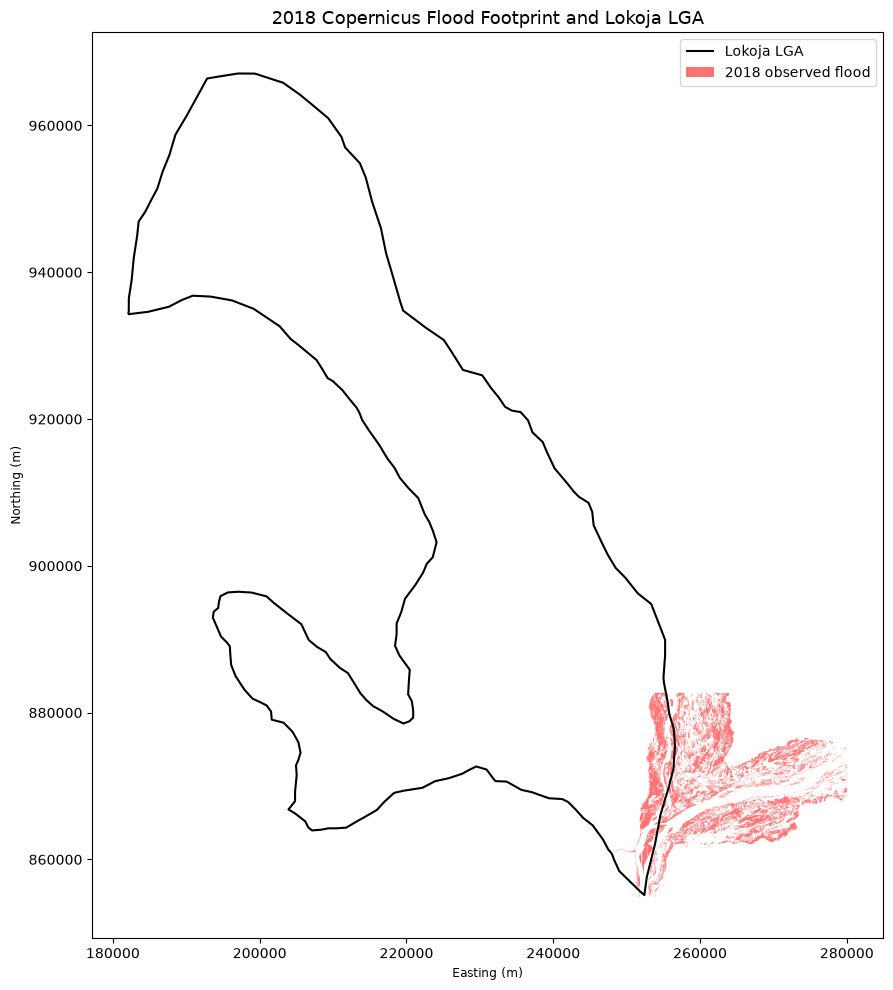

In [25]:
flood_utm = flood_gdf.to_crs("EPSG:32632")

fig, ax = plt.subplots(figsize=(10, 10))

lokoja_lga_utm.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="Lokoja LGA"
)

flood_utm.plot(
    ax=ax,
    color="red",
    alpha=0.55,
    edgecolor="none",
    label="2018 observed flood"
)

ax.set_title(
    "2018 Copernicus Flood Footprint and Lokoja LGA",
    fontsize=13
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

ax.legend()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

clean, clip and export the 2018 flood evidence

GEOMETRY REPAIR
Invalid flood geometries before: 104
Invalid flood geometries after: 0
Flood features retained: 1509

SPATIAL RESULTS
------------------------------
Flood features before clipping: 1509
Flood features after clipping: 54
Lokoja LGA area: 3181.1678 km²
Sum of clipped feature areas: 36.009 km²
Unique mapped flood area: 36.009 km²
Share of LGA area: 1.1319 %

EXPORTED FILES
/workspaces/nigeria-flood-watch/notebooks/data/processed/lokoja_lga_boundary.geojson
/workspaces/nigeria-flood-watch/notebooks/data/processed/lokoja_2018_flood_extent.geojson


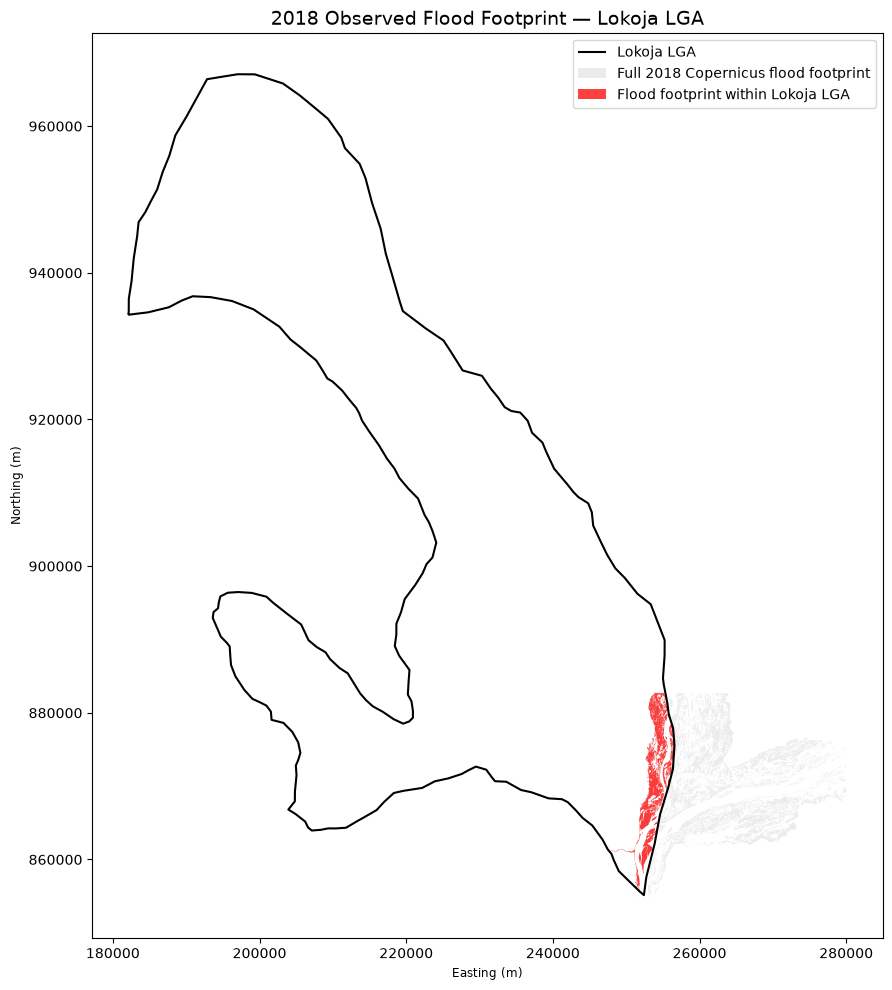


Map saved: /workspaces/nigeria-flood-watch/notebooks/data/figures/lokoja_2018_flood_extent_clipped_qa.png

FINAL QUALITY CHECK
------------------------------
LGA geometries valid: True
Clipped flood geometries valid: True
Flood CRS: EPSG:4326
LGA CRS: EPSG:4326
Flood null geometries: 0
Flood empty geometries: 0

TASK 3.4.1 PROCESSING COMPLETE


In [26]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.ops import unary_union

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ANALYSIS_CRS = "EPSG:32632"
OUTPUT_CRS = "EPSG:4326"

# Confirm source objects exist
assert "flood_gdf" in globals(), "flood_gdf is not loaded."
assert "lokoja_lga" in globals(), "lokoja_lga is not loaded."

assert flood_gdf.crs is not None, "Flood layer has no CRS."
assert lokoja_lga.crs is not None, "LGA boundary has no CRS."

# ------------------------------------------------------------
# 2. PRESERVE AND PREPARE SOURCE DATA
# ------------------------------------------------------------

flood_work = flood_gdf.copy()
lga_work = lokoja_lga.copy()

# Remove null and empty geometries from the working copies
flood_work = flood_work.loc[
    flood_work.geometry.notna() &
    ~flood_work.geometry.is_empty
].copy()

lga_work = lga_work.loc[
    lga_work.geometry.notna() &
    ~lga_work.geometry.is_empty
].copy()

# ------------------------------------------------------------
# 3. REPAIR INVALID GEOMETRIES
# ------------------------------------------------------------

invalid_before = (~flood_work.geometry.is_valid).sum()

flood_work["geometry"] = flood_work.geometry.apply(
    lambda geom: shapely.make_valid(geom)
)

# Keep polygonal components only if repair produced collections
def extract_polygonal(geom):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "Polygon":
        return geom

    if geom.geom_type == "MultiPolygon":
        return geom

    if geom.geom_type == "GeometryCollection":
        polygons = [
            part for part in geom.geoms
            if part.geom_type in ["Polygon", "MultiPolygon"]
            and not part.is_empty
        ]

        if polygons:
            return shapely.union_all(polygons)

    return None


flood_work["geometry"] = flood_work.geometry.apply(
    extract_polygonal
)

flood_work = flood_work.loc[
    flood_work.geometry.notna() &
    ~flood_work.geometry.is_empty
].copy()

invalid_after = (~flood_work.geometry.is_valid).sum()

# Repair LGA if necessary, without altering source
lga_work["geometry"] = lga_work.geometry.apply(
    lambda geom: shapely.make_valid(geom)
)

if (~lga_work.geometry.is_valid).any():
    raise ValueError("LGA boundary still contains invalid geometries.")

print("GEOMETRY REPAIR")
print("Invalid flood geometries before:", invalid_before)
print("Invalid flood geometries after:", invalid_after)
print("Flood features retained:", len(flood_work))

if invalid_after > 0:
    raise ValueError("Some flood geometries remain invalid.")

# ------------------------------------------------------------
# 4. PROJECT TO METRIC CRS
# ------------------------------------------------------------

flood_utm = flood_work.to_crs(ANALYSIS_CRS)
lga_utm = lga_work.to_crs(ANALYSIS_CRS)

# Dissolve LGA features into one clipping geometry
lga_union = lga_utm.geometry.union_all()

# ------------------------------------------------------------
# 5. CLIP FLOOD POLYGONS TO LOKOJA LGA
# ------------------------------------------------------------

flood_clipped = gpd.clip(
    flood_utm,
    lga_union,
    keep_geom_type=True
)

flood_clipped = flood_clipped.loc[
    flood_clipped.geometry.notna() &
    ~flood_clipped.geometry.is_empty
].copy()

# Ensure polygon geometries only
flood_clipped = flood_clipped.loc[
    flood_clipped.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

if len(flood_clipped) == 0:
    raise ValueError("No flood polygons intersect the Lokoja LGA boundary.")

flood_clipped["area_km2"] = (
    flood_clipped.geometry.area / 1_000_000
)

# ------------------------------------------------------------
# 6. CALCULATE AREA STATISTICS
# ------------------------------------------------------------

# Sum of individual feature areas
feature_area_km2 = flood_clipped["area_km2"].sum()

# Union area avoids double-counting overlapping polygons
flood_union = flood_clipped.geometry.union_all()
unique_flood_area_km2 = flood_union.area / 1_000_000

lga_area_km2 = lga_utm.geometry.area.sum() / 1_000_000

coverage_percentage = (
    unique_flood_area_km2 / lga_area_km2
) * 100

print("\nSPATIAL RESULTS")
print("------------------------------")
print("Flood features before clipping:", len(flood_work))
print("Flood features after clipping:", len(flood_clipped))
print("Lokoja LGA area:", round(lga_area_km2, 4), "km²")
print("Sum of clipped feature areas:", round(feature_area_km2, 4), "km²")
print("Unique mapped flood area:", round(unique_flood_area_km2, 4), "km²")
print("Share of LGA area:", round(coverage_percentage, 4), "%")

# ------------------------------------------------------------
# 7. EXPORT OUTPUTS
# ------------------------------------------------------------

# Convert to geographic CRS for GeoJSON export
lga_export = lga_utm.to_crs(OUTPUT_CRS)
flood_export = flood_clipped.to_crs(OUTPUT_CRS)

lga_output = PROCESSED_DIR / "lokoja_lga_boundary.geojson"
flood_output = PROCESSED_DIR / "lokoja_2018_flood_extent.geojson"

lga_export.to_file(lga_output, driver="GeoJSON")
flood_export.to_file(flood_output, driver="GeoJSON")

print("\nEXPORTED FILES")
print(lga_output)
print(flood_output)

# ------------------------------------------------------------
# 8. GENERATE COMPARISON MAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 10))

lga_utm.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5,
    label="Lokoja LGA"
)

flood_utm.plot(
    ax=ax,
    color="lightgrey",
    alpha=0.45,
    edgecolor="none",
    label="Full 2018 Copernicus flood footprint"
)

flood_clipped.plot(
    ax=ax,
    color="red",
    alpha=0.75,
    edgecolor="none",
    label="Flood footprint within Lokoja LGA"
)

ax.set_title(
    "2018 Observed Flood Footprint — Lokoja LGA",
    fontsize=14
)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend()
ax.set_aspect("equal")

plt.tight_layout()

map_output = FIGURES_DIR / "lokoja_2018_flood_extent_clipped_qa.png"

plt.savefig(map_output, dpi=300, bbox_inches="tight")
plt.show()

print("\nMap saved:", map_output)

# ------------------------------------------------------------
# 9. FINAL QUALITY CHECKS
# ------------------------------------------------------------

print("\nFINAL QUALITY CHECK")
print("------------------------------")
print("LGA geometries valid:", lga_export.geometry.is_valid.all())
print("Clipped flood geometries valid:", flood_export.geometry.is_valid.all())
print("Flood CRS:", flood_export.crs)
print("LGA CRS:", lga_export.crs)
print("Flood null geometries:", flood_export.geometry.isna().sum())
print("Flood empty geometries:", flood_export.geometry.is_empty.sum())

print("\nTASK 3.4.1 PROCESSING COMPLETE")


In [27]:
from pathlib import Path
import shutil

# Find the actual repository root
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / ".git").exists() and (p / "data").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not identify repository root.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Copy the existing outputs to their correct locations
outputs = {
    Path("data/processed/lokoja_lga_boundary.geojson"):
        PROCESSED_DIR / "lokoja_lga_boundary.geojson",

    Path("data/processed/lokoja_2018_flood_extent.geojson"):
        PROCESSED_DIR / "lokoja_2018_flood_extent.geojson",

    Path("data/figures/lokoja_2018_flood_extent_clipped_qa.png"):
        FIGURES_DIR / "lokoja_2018_flood_extent_clipped_qa.png",
}

for source, destination in outputs.items():
    source = current / source

    if not source.exists():
        raise FileNotFoundError(f"Missing source: {source}")

    shutil.copy2(source, destination)
    print("Copied:", destination)

print("\nRepository root:", PROJECT_ROOT)

Copied: /workspaces/nigeria-flood-watch/data/processed/lokoja_lga_boundary.geojson
Copied: /workspaces/nigeria-flood-watch/data/processed/lokoja_2018_flood_extent.geojson
Copied: /workspaces/nigeria-flood-watch/data/figures/lokoja_2018_flood_extent_clipped_qa.png

Repository root: /workspaces/nigeria-flood-watch
